In [1]:
## Import libraries
import os
import sys
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
import numpy as np
import session_info
import argparse

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering

import celltypist
from celltypist import models

import muon as mu
from muon import MuData
import scanpy as sc
import anndata as ad
import snapatac2 as snap

Multiome QC pipeline - Processing a single sample profiled with 10x multiome

Written by is10 - Teichmann lab 2024

This should be run from within the multiome environment '/nfs/team205/is10/miniconda/envs/multiome'
And compiled with paperpile so that parameters are entered correctly (or alternatively default parameters can be modified below).
Example usage from terminal: 

conda activate /nfs/team205/is10/miniconda/envs/multiome

papermill cellQC_single_sample.ipynb cellQC_single_sample_"sample".ipynb \
-p sample "sample" \
-p input_dir "input_dir" \
-p output_dir "output_dir" \
-p cell_calling_mode "cell_calling_mode" \
-p topN_cells "topN_cells" \
-p celltypist_mod "celltypist_mod" \
-p gex_median_umi_cutoff "gex_median_umi_cutoff" \
-p emptyDropsMultiOut "emptyDropsMultiOut" \
-p markerGenes "markerGenes"

#### 1. Parse arguments and set up directories

In [2]:
## Initialised parameters (actually used parameters shown below)
## Sample name - should be
sample = None ## str, required: sample name.
input_dir = None ## str, required: path to cellranger-arc output.
output_dir = None ## str, required: path to output directory
cell_calling_mode = 'union', ## str, required: should be one of ['union', 'cellranger-arc', 'multiQC', 'emptyDrops'].
topN_cells = 30000, ## int, required: number of barcodes to consider for identifying cells (should be at least approximately double the expected cell number).
celltypist_mod = None ## str, optional: path to relevant celltypist model for predicting labels.
gex_median_umi_cutoff = None ## int, optional: median number of UMIs per cluster to be used as cutoff for assigning barcodes in that cluster as cells. If None (default) this will be half of the median UMIs of cells identified by cellranger-arc.
emptyDropsMultiOut = None ## str, optional: path to csv file containing output of emptyDropsMulti. Barcode with FDR < 0.01 will be considered cells
markerGenes = None ## str, optional: path to file containing marker genes that are relevant for the expected cell types in this sample. Expects a single text file with gene symbols.

In [3]:
## Example params

#sample = "multi_HCA_THY14612130"
#input_dir = "/lustre/scratch126/cellgen/team205/is10/thygenereg/teichlab_new/cellranger/multi_HCA_THY14612130"
#output_dir = "/lustre/scratch126/cellgen/team205/is10/thygenereg/teichlab_new/multiQC/multi_HCA_THY14612130"
#cell_calling_mode = "union"
#topN_cells = 30000
#celltypist_mod = "/nfs/team205/is10/projects/thytrans/data/thymus_v4/celltypist_models/celltypist_model_HTSA_cell_type_level_4.pkl"
#gex_median_umi_cutoff = None
#emptyDropsMultiOut = "/lustre/scratch126/cellgen/team205/is10/thygenereg/teichlab_new/emptydrops/multi_HCA_THY14612130"
#markerGenes = "/nfs/team205/is10/projects/thygenereg/metadata/thymus_marker_genes.txt"


In [4]:
# Check for required parameters
required_parameters = ['sample', 'input_dir', 'output_dir', 'cell_calling_mode', 'topN_cells']

for param in required_parameters:
    if globals().get(param) is None:
        raise ValueError(f"Error: '{param}' is a required parameter and must be specified.")
        
if cell_calling_mode not in ['union', 'cellranger-arc', 'multiQC', 'emptyDrops']:
    raise ValueError("Error: 'cell_calling_mode' should be one of ['union', 'cellranger-arc', 'multiQC', 'emptyDrops']")

In [6]:
## Make output dir and change into it
output_p = (output_dir + '/')
os.makedirs(output_p, exist_ok=True)
os.chdir(output_p)

## Also make directory to save figures separately
os.makedirs((output_p + 'figures'), exist_ok=True)

#### 2. Initialise snapatac object

In [7]:
## Specify path to fragment file
fragment_file = input_dir + '/atac_fragments.tsv.gz'

## Create snap object
atac_raw = snap.pp.import_data(
    fragment_file,
    min_num_fragments = 50, ## Intentionally reducing this (default: 200) to make sure we get at least some "empty" barcodes
    chrom_sizes=snap.genome.hg38,
    file=(output_p + "snap_data_raw.h5ad"),
    sorted_by_barcode=False,
)
atac_raw

AnnData object with n_obs x n_vars = 61247 x 0 backed at '/lustre/scratch126/cellgen/team205/is10/thygenereg/teichlab_new/multiQC/multi_HCA_THY14612130/snap_data_raw.h5ad'
    obs: 'n_fragment', 'frac_dup', 'frac_mito'
    uns: 'reference_sequences'
    obsm: 'fragment_paired'

Computing fragment size distribution...


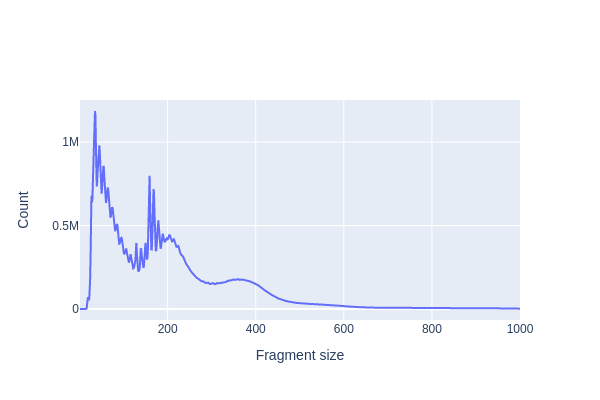

In [8]:
## Some QC - fragment length periodicity
snap.pl.frag_size_distr(atac_raw, interactive=False, out_file=(output_p + 'figures/atac_fragment_periodicity.pdf'))

100%|█████████████████████████████████████| 35.0M/35.0M [00:00<00:00, 49.2GB/s]


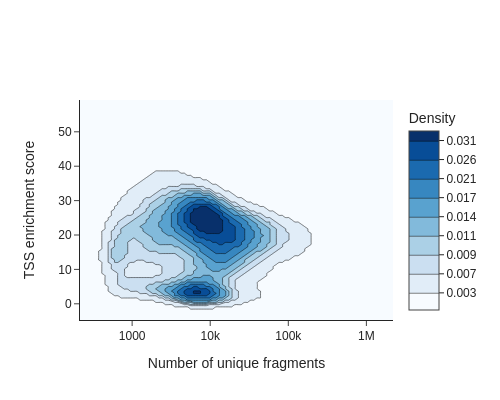

In [9]:
## Calculate TSS enrichment and plot
snap.metrics.tsse(atac_raw, snap.genome.hg38)
## TSS enrichment
snap.pl.tsse(atac_raw, interactive=False, out_file=(output_p + 'figures/atac_TSS_enrichment.pdf'))

In [10]:
## Collect info from snap atac
atac_info = pd.DataFrame({'barcode' : atac_raw.obs_names, 
              'snap_atac_fragments' : atac_raw.obs['n_fragment'],
             'snap_TSS_enrichment': atac_raw.obs['tsse']})

In [11]:
## And close snap object
atac_raw.close()

#### 3. Identify cells

In [12]:
## Incorporating info from cellranger-arc
barcode_info = pd.read_csv((input_dir + '/per_barcode_metrics.csv'))

## Some earlier cellranger-arc versions have a bug where the total number of UMIs is set to 0
## If that is the case, recompute as sum of exonic and intronic UMIs (this might slightly off but a good approximation)
if barcode_info['gex_umis_count'].max() == 0:
   barcode_info['gex_umis_count'] = barcode_info['gex_intronic_umis'] + barcode_info['gex_exonic_umis']

## Adding ATAC info
barcode_info = pd.merge(barcode_info, atac_info, on='barcode', how='left')

In [13]:
## Keeping the top N cells (by default 30000)
gex_cutoff = barcode_info['gex_umis_count'].sort_values(ascending=False).values[topN_cells]
barcode_info_top = barcode_info[barcode_info['gex_umis_count'] >= gex_cutoff].reindex()
## And of those, only those with TSS enrichment stats
barcode_info_top = barcode_info_top[np.sum(barcode_info_top.isna(), axis=1)==0]

In [14]:
## Incorporating % of intronic reads
barcode_info_top['f_intronic'] = barcode_info_top['gex_intronic_umis'] / barcode_info_top['gex_umis_count']

## And log10 norm UMI and fragment counts
barcode_info_top['gex_umis_count_log10'] = np.log10(barcode_info_top['gex_umis_count'] + 1 )
barcode_info_top['atac_fragments_log10'] = np.log10(barcode_info_top['atac_fragments'] + 1)

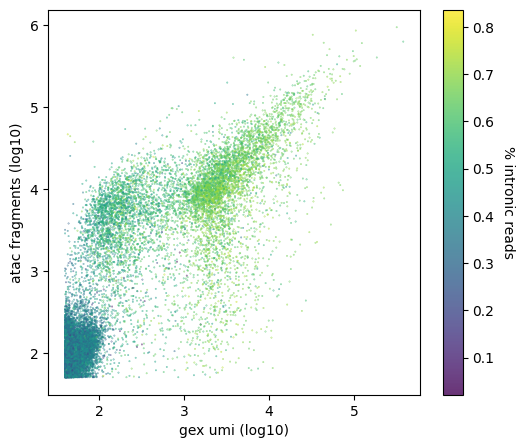

In [15]:
## Plot UMI by frags by % intronic
plt.rcParams["figure.figsize"] = [6,5]
fig, ax = plt.subplots()
f = plt.scatter(
    barcode_info_top['gex_umis_count_log10'],
    barcode_info_top['atac_fragments_log10'], 
    s=0.1, 
    alpha=0.8,
    c=barcode_info_top['f_intronic'],
    cmap='viridis'
)
plt.xlabel('gex umi (log10)')
plt.ylabel('atac fragments (log10)')
cm = fig.colorbar(f)
cm.set_label('% intronic reads', rotation=270, labelpad=15)
plt.savefig((output_p + 'figures/barcode_info_umi_by_frags_by_fIntronic.pdf'), bbox_inches = 'tight')

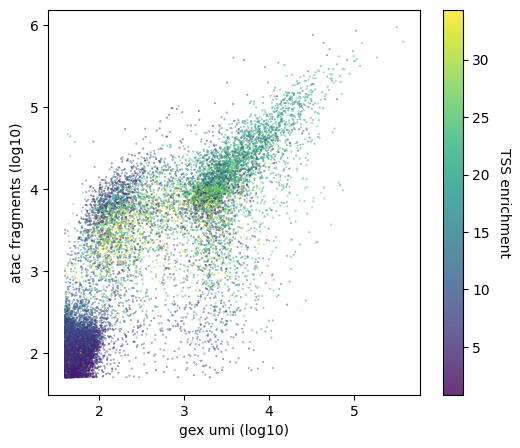

In [16]:
## Plot UMI by frags by TSS enrichment
plt.rcParams["figure.figsize"] = [6,5]

tsse_capped_q99 = barcode_info_top['snap_TSS_enrichment'].copy()
tsse_capped_q99[tsse_capped_q99 > tsse_capped_q99.quantile(0.99)] = tsse_capped_q99.quantile(0.99)

fig, ax = plt.subplots()
f = plt.scatter(
    barcode_info_top['gex_umis_count_log10'],
    barcode_info_top['atac_fragments_log10'], 
    s=0.1, 
    alpha=0.8,
    c=tsse_capped_q99,
    cmap='viridis'
)
plt.xlabel('gex umi (log10)')
plt.ylabel('atac fragments (log10)')
cm = fig.colorbar(f)
cm.set_label('TSS enrichment', rotation=270, labelpad=15)
plt.savefig((output_p + 'figures/barcode_info_umi_by_frags_by_TSSenr.pdf'), bbox_inches = 'tight')

In [17]:
## Create barcode adata object and cluster based on QC metrics:
barcode_metrics = barcode_info_top[['gex_umis_count_log10', 'atac_fragments_log10', 'snap_TSS_enrichment', 'f_intronic']]

### Scaling
scaler = StandardScaler()
scaler.fit(barcode_metrics)
barcode_metrics_scaled = scaler.transform(barcode_metrics)

### Create adata object
barcode_adata = ad.AnnData(X=np.array(barcode_metrics_scaled), obs=barcode_info_top.reset_index(drop=True))

### Run PCA, nearest neighbours, leiden clustering and UMAP
sc.pp.pca(barcode_adata)
sc.pp.neighbors(barcode_adata)
sc.tl.leiden(barcode_adata, resolution=0.2, key_added='multiQC_leiden')
sc.tl.umap(barcode_adata)

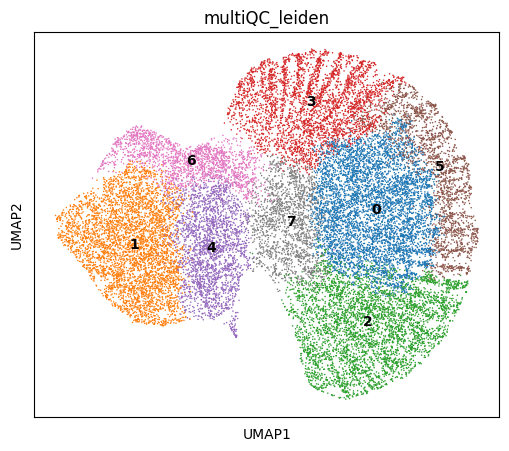

In [18]:
sc.pl.umap(barcode_adata, color='multiQC_leiden', legend_loc='on data')

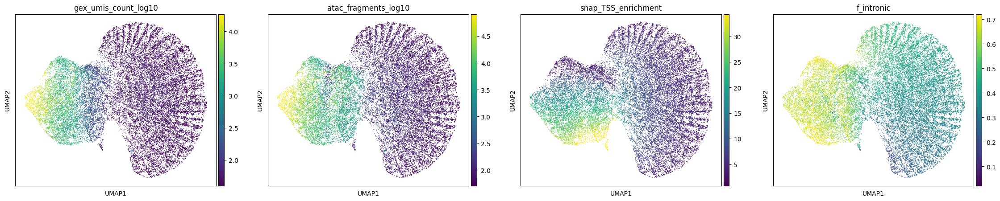

In [19]:
sc.pl.umap(barcode_adata, color=['gex_umis_count_log10', 'atac_fragments_log10', 'snap_TSS_enrichment', 'f_intronic'], vmax='p99')

In [20]:
## Now we need to match these clusters to cells
## Since we expect cellranger/EDM to be mostly correct, we will simply retain all leiden clusters with at least 30% of their barcodes labelled as cells

In [25]:
## Summarise number of barcodes per cluster that passed QC from the other methods:
fraction_passed = barcode_adata.obs.groupby('multiQC_leiden')['is_cell'].mean()
good_clust = fraction_passed.index[fraction_passed >= 0.3].tolist()

barcode_adata.obs['multiQC_is_cell'] = barcode_adata.obs['multiQC_leiden'].isin(good_clust).astype(int)

In [26]:
### Alternatively, if gex_median_umi_cutoff has been provided, simply assign all leiden clusters with a median above that cutoff as cells
print(gex_median_umi_cutoff)
if gex_median_umi_cutoff:
    median_cutoff = gex_median_umi_cutoff
    cell_clusters = gex_umi_median['multiQC_leiden'][gex_umi_median['median_gex_umi_count'] >= median_cutoff]
    barcode_adata.obs['multiQC_is_cell'] = barcode_adata.obs['multiQC_leiden'].isin(cell_clusters).astype(int)

None


In [27]:
### If emptyDropsMulti has been run, incorporate info from that as well.
if emptyDropsMultiOut:
    eDm_df = pd.read_csv((emptyDropsMultiOut + '/emptyDropsMulti.csv'))
    barcode_adata.obs['EDM_is_cell'] = barcode_adata.obs['barcode'].isin(eDm_df['Row.names'][eDm_df['FDR'] < 0.01]).astype(int)

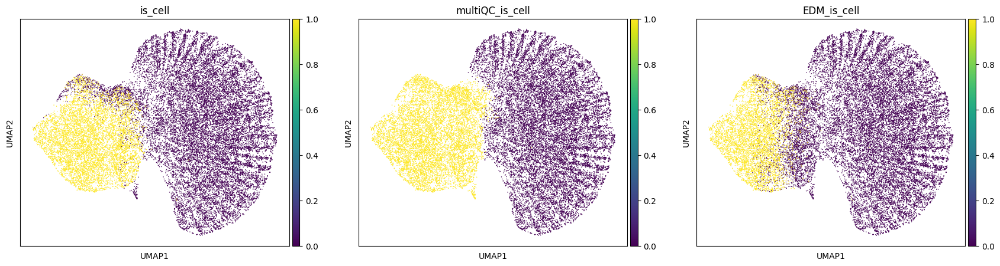

In [28]:
sc.pl.umap(barcode_adata, color=barcode_adata.obs.columns[barcode_adata.obs.columns.str.contains('is_cell')])

In [29]:
## Final cell calling
if cell_calling_mode=='union':
    barcode_adata.obs['final_cell'] = (barcode_adata.obs[barcode_adata.obs.columns[barcode_adata.obs.columns.str.contains('is_cell')]].sum(axis=1) > 0).astype(int)
if cell_calling_mode=='cellranger-arc':
    barcode_adata.obs['final_cell'] = barcode_adata.obs['is_cell'].copy()
if cell_calling_mode=='multiQC':
    barcode_adata.obs['final_cell'] = barcode_adata.obs['multiQC_is_cell'].copy()
if cell_calling_mode=='emptyDrops':
    barcode_adata.obs['final_cell'] = barcode_adata.obs['EDM_is_cell'].copy()

In [30]:
## Export this object
barcode_adata.write_h5ad((output_p + "barcode_adata.h5ad"))

#### 4. Explore RNA object

In [39]:
## Read raw GEX matrix
rna = sc.read_10x_h5((input_dir + '/raw_feature_bc_matrix.h5'))

## Subset for cells
rna = rna[rna.obs_names.isin(barcode_adata.obs['barcode'][barcode_adata.obs['final_cell']==1])]

In [40]:
## Incorporate barcode stats
rna.obs['barcode'] = rna.obs.index.tolist()
rna.obs = pd.merge(rna.obs['barcode'], barcode_adata.obs, on='barcode', how='left')
rna.obs.index = rna.obs['barcode']

In [41]:
## Standard preprocessing
rna.layers['counts'] = rna.X.copy()
rna.var["mt"] = rna.var_names.str.startswith("MT-")
rna.var["ribo"] = rna.var_names.str.startswith(("RPS","RPL"))
rna.var["hb"] = rna.var_names.str.startswith(("^HB[^(P)]"))
sc.pp.calculate_qc_metrics(rna, qc_vars=['mt','ribo','hb'], percent_top=None, log1p=False, inplace=True)

### Adding doublet scores
sc.external.pp.scrublet(rna)

### Normalise, PCA and clustering
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.pca(rna)
sc.pp.neighbors(rna)
sc.tl.leiden(rna)
sc.tl.umap(rna)

Automatically set threshold at doublet score = 0.21
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 0.1%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 30.8%


... storing 'feature_types' as categorical
... storing 'genome' as categorical


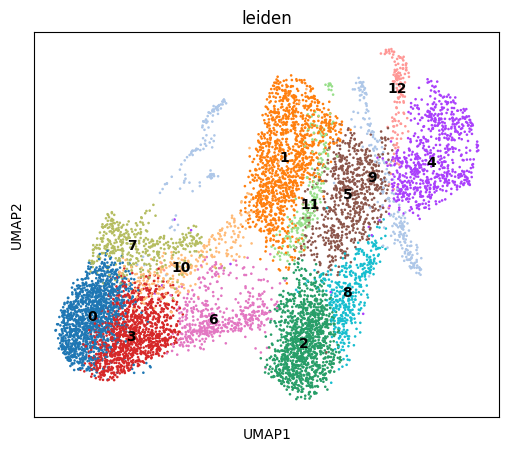

In [42]:
sc.pl.umap(rna, color='leiden', legend_loc='on data')

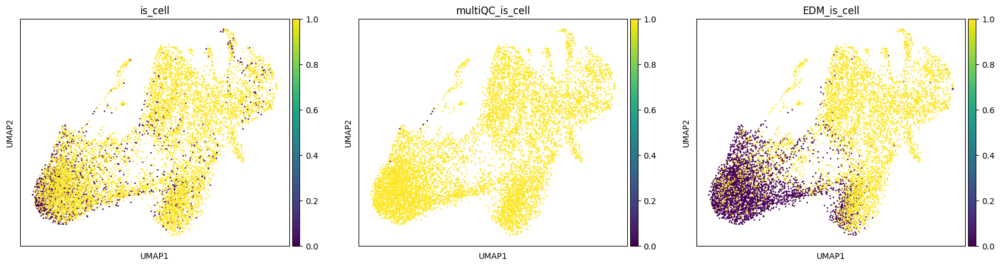

In [43]:
sc.pl.umap(rna, color=rna.obs.columns[rna.obs.columns.str.contains('is_cell')])

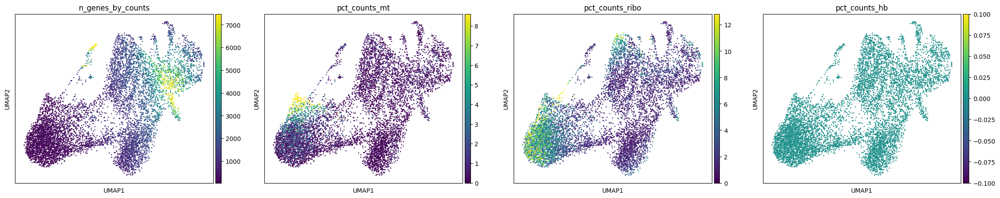

In [44]:
sc.pl.umap(rna, color=['n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribo', 'pct_counts_hb'], vmax='p99')

🔬 Input data has 8528 cells and 36601 genes
🔗 Matching reference genes in the model
🧬 7143 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


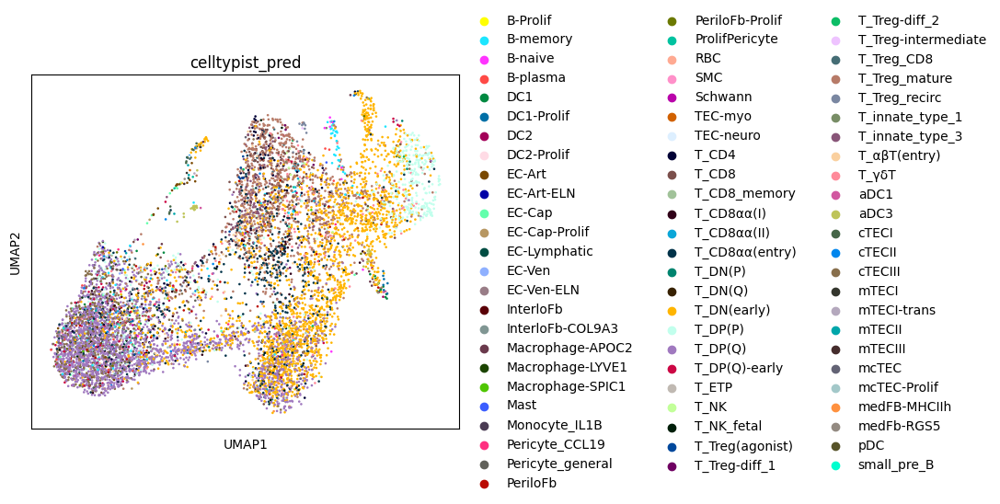

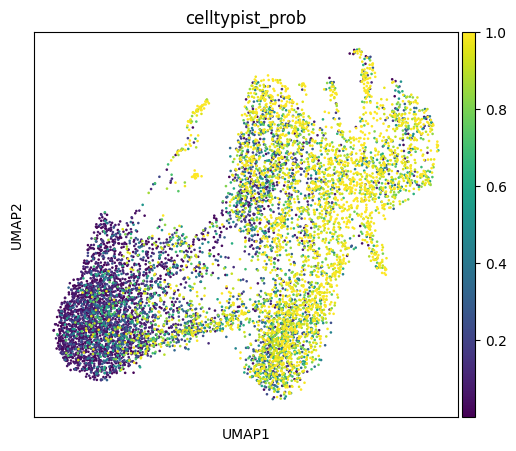

In [45]:
### If celltypist model has been provided, load and run predictions:
if celltypist_mod:
    model = models.Model.load(celltypist_mod)

    ## Predict for query cells - we don't use majority voting to not be biased by the embedding
    predictions = celltypist.annotate(rna,
                                      model = model,
                                      majority_voting = False,
                                      mode = 'best match')

    rna.obs['celltypist_pred'] = predictions.predicted_labels['predicted_labels']
    rna.obs['celltypist_prob'] = np.max(predictions.probability_matrix, 1)

    sc.pl.umap(rna, color='celltypist_pred')
    sc.pl.umap(rna, color='celltypist_prob')

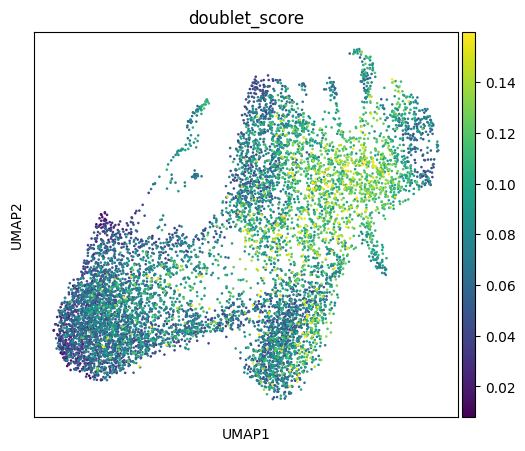

In [46]:
sc.pl.umap(rna, color='doublet_score', vmax='p99')

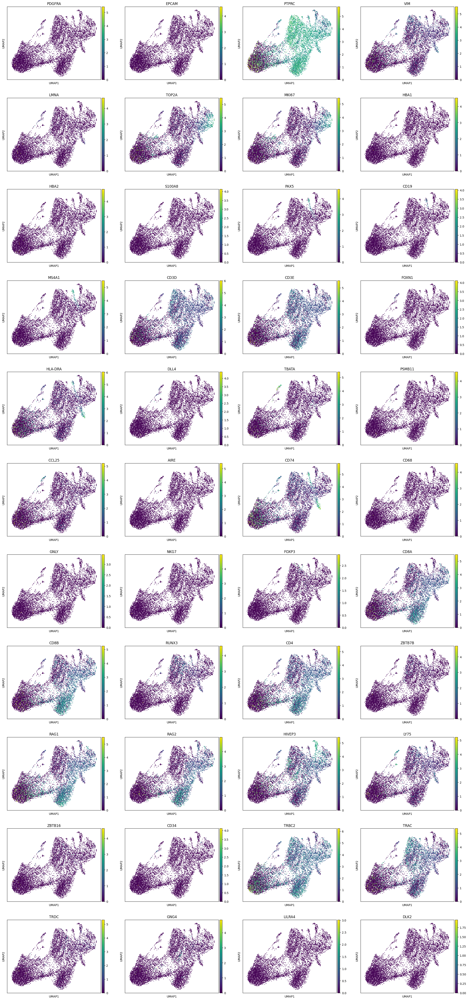

In [47]:
## If path to marker genes has been provided:
if markerGenes:
    ## Read file:
    markers = pd.read_csv(markerGenes, header=None)[0]
    ## Subset to those in the object (just in case)
    markers = markers[markers.isin(rna.var_names)]
    sc.pl.umap(rna, color=markers)

In [48]:
## Export rna object
rna.write_h5ad((output_p + "rna.h5ad"))

#### 5. Explore ATAC object

In [49]:
## Going back to snapatac
atac_raw = snap.read((output_p + "snap_data_raw.h5ad"))

In [50]:
## Filtering for cell barcodes
atac = atac_raw.subset(rna.obs_names, out=(output_p + "snap_data_filtered.h5ad"))

In [51]:
atac_raw.close()

In [52]:
## Check that the names match
sum(atac.obs_names == rna.obs_names) == len(rna.obs_names)

True

In [53]:
atac.obs = rna.obs

In [54]:
## Standard snapatac processing
## Add genomic tile matrix
snap.pp.add_tile_matrix(atac)
## Pick the top 250,000 features
snap.pp.select_features(atac, n_features=250000)
## Spectral embedding
snap.tl.spectral(atac)
## And UMAP
snap.tl.umap(atac)

Selected 250000 features.


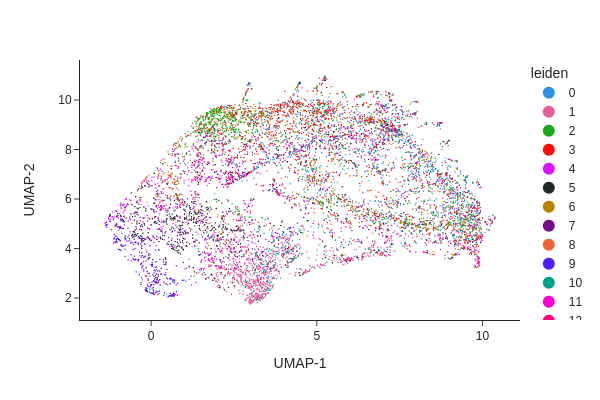

In [55]:
snap.pl.umap(atac, color='leiden', interactive=False)

In [57]:
## Run scrublet on the ATAC side to get doublet scores
snap.pp.scrublet(atac)

Simulating doublets...
Spectral embedding ...
Calculating doublet scores...


#### 6. Combine in muon object

In [65]:
## Setting up a mu object with genomic tiles and gene expression
## The X[:,:] is required to be able to access the matrix stored within the lazy element
mdata = MuData({"rna": rna, "atac_tiles": ad.AnnData(X=atac.X[:,:])})

## It's a bit more effort to take out the info from the snap object
mdata['atac_tiles'].var_names = atac.var_names
mdata['atac_tiles'].obs = rna.obs
mdata['atac_tiles'].obs['atac_doublet_score'] = atac.obs['doublet_score']
mdata['atac_tiles'].obsm['X_spectral'] = atac.obsm['X_spectral']
mdata['atac_tiles'].obsm['X_umap'] = atac.obsm['X_umap']

## Telling muon that these are the same cells across modalities
mu.pp.intersect_obs(mdata)

In [66]:
mdata

MuData object with n_obs × n_vars = 8528 × 6098696
  2 modalities
    rna:	8528 x 36601
      obs:	'barcode', 'gex_barcode', 'atac_barcode', 'is_cell', 'excluded_reason', 'gex_raw_reads', 'gex_mapped_reads', 'gex_conf_intergenic_reads', 'gex_conf_exonic_reads', 'gex_conf_intronic_reads', 'gex_conf_exonic_unique_reads', 'gex_conf_exonic_antisense_reads', 'gex_conf_exonic_dup_reads', 'gex_exonic_umis', 'gex_conf_intronic_unique_reads', 'gex_conf_intronic_antisense_reads', 'gex_conf_intronic_dup_reads', 'gex_intronic_umis', 'gex_conf_txomic_unique_reads', 'gex_umis_count', 'gex_genes_count', 'atac_raw_reads', 'atac_unmapped_reads', 'atac_lowmapq', 'atac_dup_reads', 'atac_chimeric_reads', 'atac_mitochondrial_reads', 'atac_fragments', 'atac_TSS_fragments', 'atac_peak_region_fragments', 'atac_peak_region_cutsites', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'gex_umis_count_log10', 'atac_fragments_log10', 'multiQC_leiden', 'multiQC_is_cell', 'EDM_is_cell', 'final_cell', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'leiden', 'celltypist_pred', 'celltypist_prob', 'atac_doublet_score'
      var:	'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
      uns:	'scrublet', 'log1p', 'pca', 'neighbors', 'leiden', 'umap', 'leiden_colors', 'celltypist_pred_colors'
      obsm:	'X_pca', 'X_umap'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'distances', 'connectivities'
    atac_tiles:	8528 x 6062095
      obs:	'barcode', 'gex_barcode', 'atac_barcode', 'is_cell', 'excluded_reason', 'gex_raw_reads', 'gex_mapped_reads', 'gex_conf_intergenic_reads', 'gex_conf_exonic_reads', 'gex_conf_intronic_reads', 'gex_conf_exonic_unique_reads', 'gex_conf_exonic_antisense_reads', 'gex_conf_exonic_dup_reads', 'gex_exonic_umis', 'gex_conf_intronic_unique_reads', 'gex_conf_intronic_antisense_reads', 'gex_conf_intronic_dup_reads', 'gex_intronic_umis', 'gex_conf_txomic_unique_reads', 'gex_umis_count', 'gex_genes_count', 'atac_raw_reads', 'atac_unmapped_reads', 'atac_lowmapq', 'atac_dup_reads', 'atac_chimeric_reads', 'atac_mitochondrial_reads', 'atac_fragments', 'atac_TSS_fragments', 'atac_peak_region_fragments', 'atac_peak_region_cutsites', 'snap_atac_fragments', 'snap_TSS_enrichment', 'f_intronic', 'gex_umis_count_log10', 'atac_fragments_log10', 'multiQC_leiden', 'multiQC_is_cell', 'EDM_is_cell', 'final_cell', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'doublet_score', 'predicted_doublet', 'leiden', 'celltypist_pred', 'celltypist_prob', 'atac_doublet_score'
      obsm:	'X_spectral', 'X_umap'

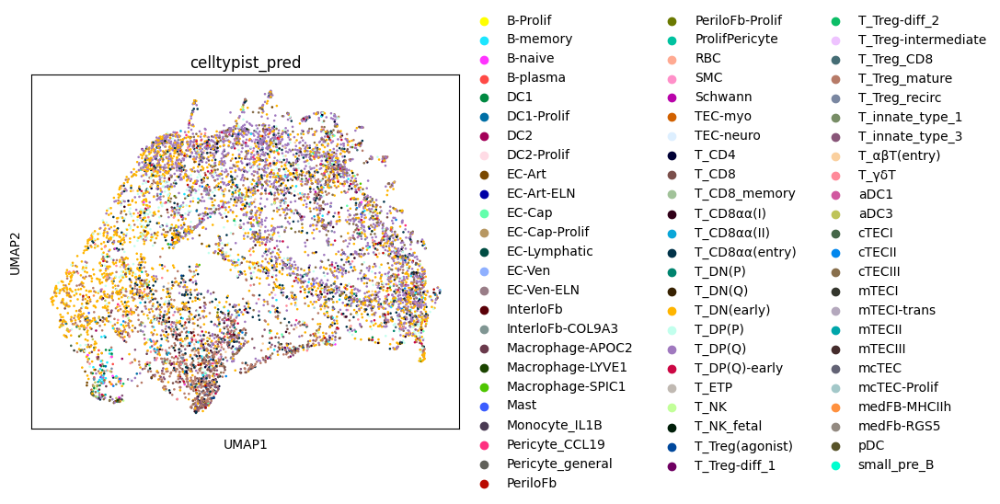

In [67]:
sc.pl.umap(mdata['atac_tiles'], color='celltypist_pred')

In [68]:
## Closing the atac object
atac.close()

In [69]:
## Add information about sample and modify obs_names
mdata.obs['sample_ID'] = sample
mdata.obs['sample_barcode'] = sample + '-' + mdata.obs_names
mdata.obs.index = mdata.obs['sample_barcode'].tolist().copy()
mdata['rna'].obs.index = mdata.obs['sample_barcode'].tolist().copy()
mdata['atac_tiles'].obs.index = mdata.obs['sample_barcode'].tolist().copy()

In [70]:
## Export muon object
mdata.write((output_p + "multiome.h5mu"))

/nfs/team205/is10/miniconda/envs/multiome/lib/python3.9/site-packages/anndata/_core/anndata.py:1235: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

... storing 'sample_ID' as categorical


In [71]:
## Also export all barcode names (useful downstream for souporcell)
pd.DataFrame(mdata.obs_names).to_csv((output_p + "barcodes.tsv"), header = None, index=None)

In [76]:
## And extract all barcode info so that we don't have to read the mdata object every time
mdata['rna'].obs.to_csv((output_p + "multiQC_barcode_info.tsv"))